In [39]:
import torch
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch import optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm

In [40]:
class CNN(nn.Module):
    def __init__(self, in_channels, num_classes=10):
        """
        Define the layers of the convolutional neural network.

        Parameters:
            in_channels: int
                The number of channels in the input image. For MNIST, this is 1 (grayscale images).
            num_classes: int
                The number of classes we want to predict, in our case 10 (digits 0 to 9).
        """
        super(CNN, self).__init__()

        # First convolutional layer: 1 input channel, 8 output channels, 3x3 kernel, stride 1, padding 1
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=8, kernel_size=3, stride=1, padding=1)
        # Max pooling layer: 2x2 window, stride 2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # Second convolutional layer: 8 input channels, 16 output channels, 3x3 kernel, stride 1, padding 1
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, stride=1, padding=1)
        # Fully connected layer: 16*7*7 input features (after two 2x2 poolings), 10 output features (num_classes)
        self.fc1 = nn.Linear(16 * 7 * 7, num_classes)

    def forward(self, x):
        """
        Define the forward pass of the neural network.

        Parameters:
            x: torch.Tensor
                The input tensor.

        Returns:
            torch.Tensor
                The output tensor after passing through the network.
        """
        x = F.relu(self.conv1(x))  # Apply first convolution and ReLU activation
        # 8, 28, 28 -> 8 outputs de 28*28 el tamaño de la imagen
        x = self.pool(x)           # Apply max pooling (window 2*2 stride 2)
        # 8, 14, 14 -> 8 outputs de 14 * 14 despues del pool
        x = F.relu(self.conv2(x))  # Apply second convolution and ReLU activation
        # 16, 14, 14 
        x = self.pool(x)           # Apply max pooling
        # 14, 7, 7 despues del pooling
        x = x.reshape(x.shape[0], -1)  # Flatten the tensor
        x = self.fc1(x)            # Apply fully connected layer
        return x

In [41]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [42]:
input_size = 784  # 28x28 pixels (not directly used in CNN)
num_classes = 10  # digits 0-9
learning_rate = 0.001
batch_size = 64
num_epochs = 10  # Reduced for demonstration purposes

In [43]:
train_dataset = datasets.MNIST(root="dataset/", download=True, train=True, transform=transforms.ToTensor())
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = datasets.MNIST(root="dataset/", download=True, train=False, transform=transforms.ToTensor())
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

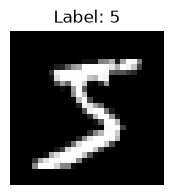

In [44]:
import matplotlib.pyplot as plt

# Get the first image and label from the training dataset
image, label = train_dataset[0]

# Permute the dimensions of the image tensor to (height, width, channels) for plotting
image = image.permute(1, 2, 0)

# Set the figure size to make the image smaller (e.g., 2x2 inches)
plt.figure(figsize=(2, 2))

# Plot the image
plt.imshow(image.squeeze(), cmap='gray')
plt.title(f"Label: {label}")
plt.axis('off')  # Hide the axes
plt.show()

In [45]:
model = CNN(in_channels=1, num_classes=num_classes).to(device)

In [46]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [47]:
def check_accuracy(loader, model):
    """
    Checks the accuracy of the model on the given dataset loader.

    Parameters:
        loader: DataLoader
            The DataLoader for the dataset to check accuracy on.
        model: nn.Module
            The neural network model.
    """
    if loader.dataset.train:
        print("Checking accuracy on training data")
    else:
        print("Checking accuracy on test data")

    num_correct = 0
    num_samples = 0
    model.eval()  # Set the model to evaluation mode
    running_val_loss = 0
    num_samples = 0

    with torch.no_grad():  # Disable gradient calculation
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            # Forward pass: compute the model output
            scores = model(x)
            loss = criterion(scores, y)
            running_val_loss += loss.item() * x.size(0)

            _, predictions = scores.max(1)  # Get the index of the max log-probability
            num_correct += (predictions == y).sum()  # Count correct predictions
            num_samples += predictions.size(0)  # Count total samples

        # Calculate accuracy
        accuracy = float(num_correct) / float(num_samples)
        losses = running_val_loss / num_samples
        print(f"Got {num_correct}/{num_samples} with accuracy {accuracy*100:.2f}%")

    model.train()  # Set the model back to training mode
    return accuracy, losses

In [48]:
def train(train_l, test_v, model, optimizer):
    train_losses = []
    train_accs = []
    val_accs = []
    val_losses = []
    for epoch in range(num_epochs):
        running_loss = 0
        correct = 0
        total = 0
        print(f"Epoch [{epoch + 1}/{num_epochs}]")
        for batch_index, (data, targets) in enumerate(tqdm(train_l)):
            # Move data and targets to the device (GPU/CPU)
            data = data.to(device)
            targets = targets.to(device)

            # Forward pass: compute the model output
            scores = model(data)
            loss = criterion(scores, targets)

            # Backward pass: compute the gradients
            optimizer.zero_grad()
            loss.backward()

            # Optimization step: update the model parameters
            optimizer.step()
            running_loss += loss.item() * data.size(0)
            predicted = scores.argmax(dim=1)
            correct += (predicted == targets).sum().item()
            total += targets.size(0)

        train_losses.append(running_loss / total)
        train_accs.append(correct / total)
        val_acc, val_loss = check_accuracy(test_v, model)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
    return train_losses, train_accs, val_losses, val_accs

In [49]:
def run_experiment(train_l, test_l, seed=0):
    torch.manual_seed(seed)
    model = CNN(in_channels=1, num_classes=num_classes).to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    return train(train_l, test_l, model, optimizer)

In [50]:
train_losses, train_accs, val_losses, val_accs = run_experiment(train_loader, test_loader)

Epoch [1/10]


100%|██████████| 938/938 [00:23<00:00, 40.58it/s]


Checking accuracy on test data
Got 9683/10000 with accuracy 96.83%
Epoch [2/10]


100%|██████████| 938/938 [00:27<00:00, 34.67it/s]


Checking accuracy on test data
Got 9788/10000 with accuracy 97.88%
Epoch [3/10]


100%|██████████| 938/938 [00:28<00:00, 33.12it/s]


... (11 outputs left out)

100%|██████████| 938/938 [00:27<00:00, 34.59it/s]


Checking accuracy on test data
Got 9880/10000 with accuracy 98.80%
Epoch [10/10]


100%|██████████| 938/938 [00:27<00:00, 34.40it/s]


Checking accuracy on test data
Got 9877/10000 with accuracy 98.77%


In [51]:
# Final accuracy check on training and test sets
check_accuracy(train_loader, model)
check_accuracy(test_loader, model)

Checking accuracy on training data
Got 4526/60000 with accuracy 7.54%
Checking accuracy on test data
Got 772/10000 with accuracy 7.72%


(0.0772, 2.3066520217895508)

Ejercicios:
1) Graficar learning curves.
2) Comparar performance para distinto número de capas convolucionales.
3) Preprocesar el input para que las imagenes sean 1 o 0 (blanco o negro, no gris).

In [52]:
import matplotlib.pyplot as plt

def plot(train_losses, train_accs, val_losses, val_accs):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label="Train loss")
    plt.plot(epochs, val_losses, label="Validation loss")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, label="Train accuracy")
    plt.plot(epochs, val_accs, label="Validation accuracy")
    plt.xlabel("Época")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

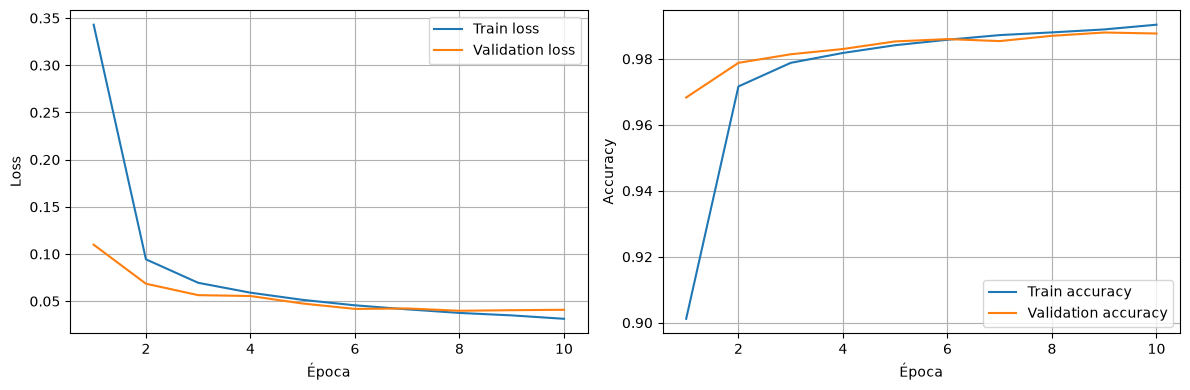

In [53]:
plot(train_losses, train_accs, val_losses, val_accs)

In [54]:
import time

class FlexCNN(nn.Module):
    def __init__(self, n_conv, in_channels=1, num_classes=10):
        super().__init__()
        layers, c_in = [], in_channels
        for i in range(n_conv):
            c_out = 8 * 2**i                      # 8, 16, 32, ...
            layers += [nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        with torch.no_grad():                     # calcula el tamaño del flatten
            n_flat = self.features(torch.zeros(1, in_channels, 28, 28)).numel()
        self.fc = nn.Linear(n_flat, num_classes)

    def forward(self, x):
        return self.fc(self.features(x).flatten(1))

In [55]:
results = {}
num_epochs_perf = 4
for n_conv in [1, 2, 3]:
    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        m = FlexCNN(n_conv).to(device)
        opt = optim.Adam(m.parameters(), lr=learning_rate)
        n_params = sum(p.numel() for p in m.parameters())

        train_time = 0
        for epoch in range(num_epochs_perf):
            t0 = time.time()
            for data, targets in train_loader:
                data, targets = data.to(device), targets.to(device)
                loss = criterion(m(data), targets)
                opt.zero_grad()
                loss.backward()
                opt.step()
            if device == "cuda":
                torch.cuda.synchronize()
            train_time += time.time() - t0        # solo cuenta el entrenamiento

        acc, val_loss = check_accuracy(test_loader, m)   # tu versión corregida
        results.setdefault(n_conv, []).append((acc, val_loss, train_time, n_params))

Checking accuracy on test data
Got 9738/10000 with accuracy 97.38%
Checking accuracy on test data
Got 9736/10000 with accuracy 97.36%
Checking accuracy on test data
Got 9702/10000 with accuracy 97.02%
Checking accuracy on test data
Got 9842/10000 with accuracy 98.42%
Checking accuracy on test data
Got 9812/10000 with accuracy 98.12%
Checking accuracy on test data
Got 9841/10000 with accuracy 98.41%
Checking accuracy on test data
Got 9834/10000 with accuracy 98.34%
Checking accuracy on test data
Got 9848/10000 with accuracy 98.48%
Checking accuracy on test data
Got 9852/10000 with accuracy 98.52%


In [56]:
import numpy as np
print("capas | params | acc test (media ± std) | tiempo total (s)")
for n_conv, r in results.items():
    accs = [x[0] for x in r]
    print(f"{n_conv:5d} | {r[0][3]:6d} | {np.mean(accs)*100:.2f} ± {np.std(accs)*100:.2f}      | {np.mean([x[2] for x in r]):.0f}")

capas | params | acc test (media ± std) | tiempo total (s)
    1 |  15770 | 97.25 ± 0.17      | 85
    2 |   9098 | 98.32 ± 0.14      | 79
    3 |   8778 | 98.45 ± 0.08      | 85


In [57]:
binarize = transforms.Compose([
    transforms.ToTensor(),                           # valores en [0, 1]
    transforms.Lambda(lambda x: (x > 0.5).float()),  # >0.5 -> 1.0, si no -> 0.0
])

train_dataset_bin = datasets.MNIST(root="dataset/", download=True, train=True, transform=binarize)
test_dataset_bin  = datasets.MNIST(root="dataset/", download=True, train=False, transform=binarize)

train_loader_bin = DataLoader(train_dataset_bin, batch_size=batch_size, shuffle=True)
test_loader_bin  = DataLoader(test_dataset_bin, batch_size=batch_size, shuffle=False)

tensor([0., 1.])


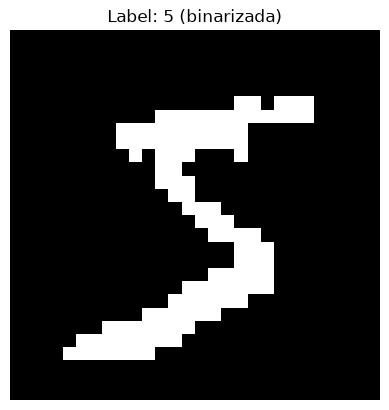

In [58]:
img, label = train_dataset_bin[0]
print(img.unique())          # tiene que dar tensor([0., 1.])

plt.imshow(img.squeeze(), cmap="gray")
plt.title(f"Label: {label} (binarizada)")
plt.axis("off")
plt.show()

In [59]:
train_bin_losses, train_bin_accs, val_bin_losses, val_bin_accs = run_experiment(train_loader_bin, test_loader_bin)

Epoch [1/10]


100%|██████████| 938/938 [00:21<00:00, 43.96it/s]


Checking accuracy on test data
Got 9622/10000 with accuracy 96.22%
Epoch [2/10]


100%|██████████| 938/938 [00:21<00:00, 44.03it/s]


Checking accuracy on test data
Got 9721/10000 with accuracy 97.21%
Epoch [3/10]


100%|██████████| 938/938 [00:21<00:00, 44.48it/s]


... (11 outputs left out)

100%|██████████| 938/938 [00:20<00:00, 45.06it/s]


Checking accuracy on test data
Got 9829/10000 with accuracy 98.29%
Epoch [10/10]


100%|██████████| 938/938 [00:21<00:00, 44.65it/s]


Checking accuracy on test data
Got 9858/10000 with accuracy 98.58%


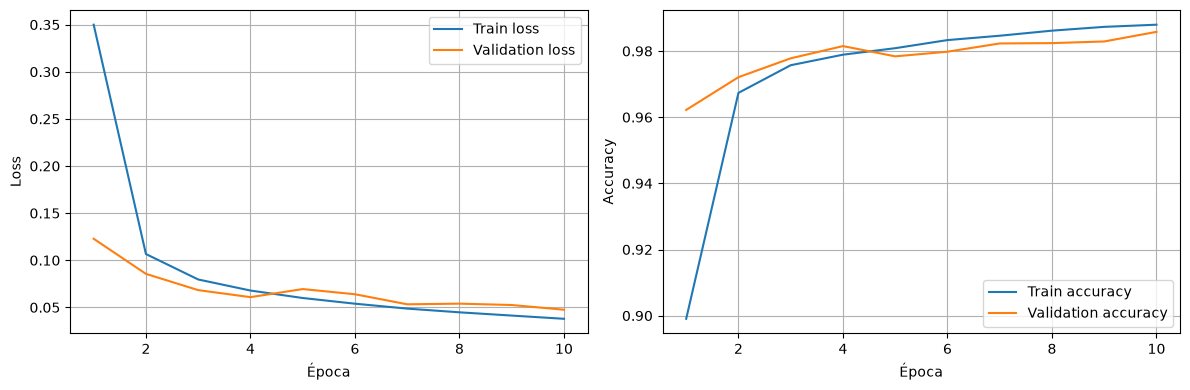

In [60]:
plot(train_bin_losses, train_bin_accs, val_bin_losses, val_bin_accs)